---
title: "Simple Interaction"
subtitle: "DS 2023 | Communicating with Data"
---

<img src="https://ipywidgets.readthedocs.io/en/stable/_images/interact.gif" />

[Source](https://ipywidgets.readthedocs.io/en/stable/)

## Overview

When exploring data, you often want to try different parameters — bin sizes, smoothing windows, color mappings — without rerunning cells by hand.

Widgets let you expose those parameters as sliders, dropdowns, and checkboxes so you can adjust them continuously.

This is useful for two reasons.

- First, it speeds up your own exploratory analysis.

- Second, it lets you share a notebook where others can explore the data themselves without touching any code.

The Jupyter Widgets library `ipywidgets` provides a nice collection of widgets you can use to allow users to interact with your code.

The `@interact` decorator connects them to your functions in a quick way.

This notebook demonstrates the use of `@interact`.

## Set up

To use Jupyter Widgets, import the `ipywidgets` library.

Here, we begin by just grabbing the `display` asset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display

In [2]:
sns.set_style('white')

## A simple example

Let's begin by looking at a simple line plot from the flights dataset.

In [24]:
flights = sns.load_dataset('flights')
flights["date"] = pd.to_datetime(flights["year"].astype(str) + "-" + flights["month"].astype(str),  format="%Y-%b")
flights = flights.set_index('date')

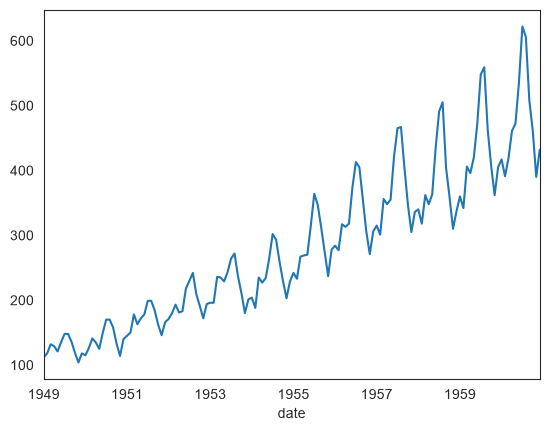

In [25]:
flights['passengers'].plot()
plt.show()

As you know by now, there are many parameters you can adjust when creating plots. 

Here we adjust figure size and the kind of plot.

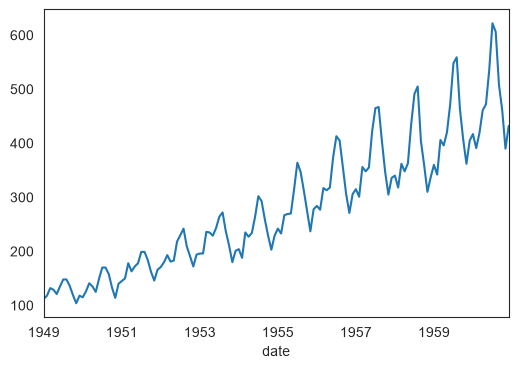

In [26]:
flights['passengers'].plot(figsize=(6,4), kind='line')
plt.show()

Widgets let you put these paramters into widgets that the user can enter directly into the notebook.

A simple way to do that is use `interact`.

The `@interact` is a decorator that inspects a function's arguments and creates widgets automatically.

It infers the widget type from the default value: an integer becomes a slider, a list becomes a dropdown, a boolean becomes a checkbox.

You can also pass a tuple `(min, max, step)` to override the slider range for a numeric argument, or a list to force a dropdown.

In [6]:
@interact()
def plot_flights(w=6, h=4, kind='line'):
    flights['passengers'].plot(figsize=(w,h), kind=kind)
    plt.show()

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

In [7]:
@interact(kind=['line', 'bar'])
def plot_flights(w=6, h=4, kind='line'):
    flights['passengers'].plot(figsize=(w,h), kind=kind)
    plt.show()

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

In [8]:
@interact(kind=['line', 'area'], window=(1,20,1), alpha=(.1,1.,.1))
def plot_flights(w=6, h=4, kind='line', window=1, alpha=1):
    flights["passengers"].rolling(window=window).mean().plot(figsize=(w,h), kind=kind, alpha=alpha)
    plt.suptitle(f"Rolling Mean of Passengers (w={window})")
    plt.show()

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

## Interacting with other libraries

`@interact` works with any plotting library that renders output in a cell.

Indeed, it can work with anything that take parameters and produces and output.

Here we use the decorator with Plotly's `parallel_categories` chart function on the Penguins dataset.

In [11]:
penguins = sns.load_dataset('penguins').dropna()
penguins_groups = ['species', 'island', 'sex']
penguin_measures = ['bill_length_mm','bill_depth_mm','flipper_length_mm','body_mass_g']
penguins[penguins_groups] = penguins[penguins_groups].astype('category')

In [12]:
@interact(
    color=penguins_groups, 
    cmap=px.colors.named_colorscales(),
    h=(100,1000,1), 
    w=(100,2000,1))
def plot_alluvial(color='species', h=500, w=700,cmap="YlGnBu"):
    fig = px.parallel_categories(
        penguins, 
        dimensions=penguins_groups, 
        color=penguins[color].cat.codes, 
        color_continuous_scale=cmap,
        width=w, height=h
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    fig.show()

interactive(children=(Dropdown(description='color', options=('species', 'island', 'sex'), value='species'), In…

## Colormap viewer

A practical utility: browse all available matplotlib colormaps interactively.
The second version filters out reversed variants (names ending in `_r`) and adds a checkbox to apply the reversal manually.

In [51]:
@interact(cmap = [cm for cm in plt.colormaps])
def show_colors(cmap):
    cmap = plt.get_cmap(cmap)
    display(cmap)

interactive(children=(Dropdown(description='cmap', options=('magma', 'inferno', 'plasma', 'viridis', 'cividis'…

In [52]:
@interact(cmap=[cm for cm in plt.colormaps if '_r' not in cm])
def show_colors(cmap, reverse=False):
    if reverse:
        cmap += '_r'
    cmap = plt.get_cmap(cmap)
    display(cmap)

interactive(children=(Dropdown(description='cmap', options=('magma', 'inferno', 'plasma', 'viridis', 'cividis'…

## Updating EDA parameters

A common use case: tune distribution plots without rerunning cells.
Here, a dropdown selects the column and sliders control the histogram bin count and KDE bandwidth.

In [13]:
@interact(
    bins=(1,100,1),
    bw=(.1,2.0,.1),
    col=penguin_measures
)
def plot_measures(col='price', bins=30, bw=.5):
    fig, ax = plt.subplots(1, 2, figsize=(10,4), layout='constrained')
    penguins.plot.hist(y=col, ax=ax[0], bins=bins, legend=False)
    penguins.plot.density(y=col, ax=ax[1], bw_method=bw, legend=False)
    fig.suptitle(col.replace("_", " ").upper())
    plt.show()

interactive(children=(Dropdown(description='col', options=('bill_length_mm', 'bill_depth_mm', 'flipper_length_…

## Labeling widgets

By default, `@interact` uses the argument name as the widget label.
Pass an explicit widget constructor — such as `widgets.IntSlider(description="Figure height")` — to use a friendlier label.

You can also display and reuse a widget object independently of `@interact`.

In [14]:
import ipywidgets as widgets

In [15]:
widgets.FloatSlider(1, min=.1, max=5, step=.1)

FloatSlider(value=1.0, max=5.0, min=0.1)

In [16]:
w = widgets.FloatSlider(1, min=.1, max=5, step=.1)
w

FloatSlider(value=1.0, max=5.0, min=0.1)

In [17]:
w

FloatSlider(value=1.0, max=5.0, min=0.1)

In [18]:
@interact(
    kind=widgets.Select(options=['bar', 'barh', 'line', 'pie'], description="Plot type"),
    ascend=widgets.Checkbox(False, description='Ascending?'),
    color=widgets.ColorPicker(description="Plot color"),
    lw=widgets.FloatSlider(min=.1, max=5, step=.1, description="Line width"),
    h = widgets.IntSlider(4, min=1, max=10, step=1, description="Figure height"),
    w = widgets.IntSlider(5, min=1, max=10, step=1, description="Figure width"),
    despine = widgets.Checkbox(description="Remove top and right spines")
)
def plot_country_counts(w, h, kind='line', ascend=False, color='tab:blue', lw=1, despine=False):    
    kw = {
        'figsize': (w, h),
        'kind': kind
    }
    if kind == 'line':
        kw['lw'] = lw
        kw['color'] = color
    if kind in ['bar', 'barh']:
        kw['color'] = color

    print(kw)
        
    penguins['species'].value_counts()\
        .sort_values(ascending=ascend)\
        .plot(**kw)
    if despine:
        sns.despine()
    plt.show()

interactive(children=(IntSlider(value=5, description='Figure width', max=10, min=1), IntSlider(value=4, descri…

## Slowing down updates

By default, `@interact` re-runs the function on every widget change.

You can use `@interact_manual` to add a "Run" button instead — useful when the computation is slow.

In [19]:
from ipywidgets import interact_manual

@interact_manual(kind=['line', 'area'], window=(1,20,1), alpha=(.1,1.,.1))
def plot_flights_manual(w=6, h=4, kind='line', window=1, alpha=1):
    flights["passengers"].rolling(window=window).mean().plot(figsize=(w,h), kind=kind, alpha=alpha)
    plt.suptitle(f"Rolling Mean of Passengers (w={window})")
    plt.show()

interactive(children=(IntSlider(value=6, description='w', max=18, min=-6), IntSlider(value=4, description='h',…

## Selecting axes

A common EDA pattern is to let the user pick which columns map to `x`, `y`, and `hue`.

In [21]:
@interact(x=penguin_measures, y=penguin_measures, hue=penguins_groups)
def scatter(x='bill_length_mm', y='bill_depth_mm', hue='species'):
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.scatterplot(data=penguins, x=x, y=y, hue=hue, ax=ax)
    plt.show()

interactive(children=(Dropdown(description='x', options=('bill_length_mm', 'bill_depth_mm', 'flipper_length_mm…

## Freezing parameters with `fixed()`

Wrap a value in `fixed()` to prevent `@interact` from creating a widget for it.

The function still receives the value &mdash; it just isn't exposed to the user.

In [22]:
from ipywidgets import fixed

@interact(x=penguin_measures, y=penguin_measures, hue=fixed('species'))
def scatter_fixed(x='bill_length_mm', y='bill_depth_mm', hue='species'):
    sns.scatterplot(data=penguins, x=x, y=y, hue=hue)
    plt.show()

interactive(children=(Dropdown(description='x', options=('bill_length_mm', 'bill_depth_mm', 'flipper_length_mm…